# Session 2 – SQL, Exploratory Data Analysis (EDA) and Data Visualisation
**Microsoft Machine Learning and AI Course· Mata Sundri College for Women · Sat 31 Oct 2026 · Online**

Today we will ask business questions of a small **online-store database** using **SQL**, explore data with an **EDA checklist**, and draw charts that answer a question.

The case study (CS-02) uses Delhi air-quality data.

In [ ]:
import sqlite3  #python package that let us implement SQL in python notebook
import pandas as pd

con = sqlite3.connect(':memory:')
con.executescript("""
CREATE TABLE orders (order_id TEXT, city TEXT, product TEXT, quantity INTEGER, price INTEGER);
INSERT INTO orders VALUES
 ('O1','Delhi','Earbuds',1,1499),     ('O2','Mumbai','Kurti',2,799),       ('O3','Delhi','Jeans',1,1299),
 ('O4',NULL,'Earbuds',1,1499),        ('O5','Pune','Smart Watch',4,2999),  ('O3','Delhi','Jeans',1,1299),
 ('O6','Mumbai','Lunch Box',-1,499),  ('O7','Delhi','Kurti',3,799),        ('O8','Jaipur','Earbuds',1,1499),
 ('O9','Delhi','Smart Watch',1,2999), ('O10','Mumbai','Jeans',2,1299),     ('O11','Delhi','Lunch Box',1,499);
""")
q = lambda sql: pd.read_sql_query(sql, con)
print('Table ready ✅')

Table ready ✅


In [ ]:
# Step 1 – Shape: how many rows? how many unique orders?

q("SELECT COUNT(*) AS rows, COUNT(DISTINCT order_id) AS unique_orders FROM orders")

,rows,unique_orders
0,12,11


In [ ]:
# Step 2 – Missing values and duplicates

q("""SELECT SUM(city IS NULL)                     AS missing_city,
            COUNT(*) - COUNT(DISTINCT order_id)   AS duplicates
     FROM orders""")

,missing_city,duplicates
0,1,1


In [ ]:
# Step 3 – Distribution: what is typical? what is the range?

q("""
SELECT MIN(quantity) AS min_qty,
MAX(quantity) AS max_qty,
ROUND(AVG(quantity * price), 0) AS avg_amount,
MIN(quantity * price) AS min_amount,
MAX(quantity * price) AS max_amount
     FROM orders""")

,min_qty,max_qty,avg_amount,min_amount,max_amount
0,-1,4,2390.0,-499,11996


In [ ]:
# Step 4 – Outliers: show the unusual rows

q("SELECT * FROM orders WHERE quantity <= 0 OR quantity * price > 5000")

,order_id,city,product,quantity,price
0,O5,Pune,Smart Watch,4,2999
1,O6,Mumbai,Lunch Box,-1,499


In [ ]:
# Step 5 – Groups and patterns: revenue by city

q("""SELECT city,
COUNT(*) AS orders,
SUM(quantity * price) AS revenue
     FROM orders
     GROUP BY city
     ORDER BY revenue DESC""")

,city,orders,revenue
0,Pune,1,11996
1,Delhi,6,9992
2,Mumbai,3,3697
3,Jaipur,1,1499
4,None,1,1499


If we dont perform EDA and direftly goes for Visualisation follwing will be the chart

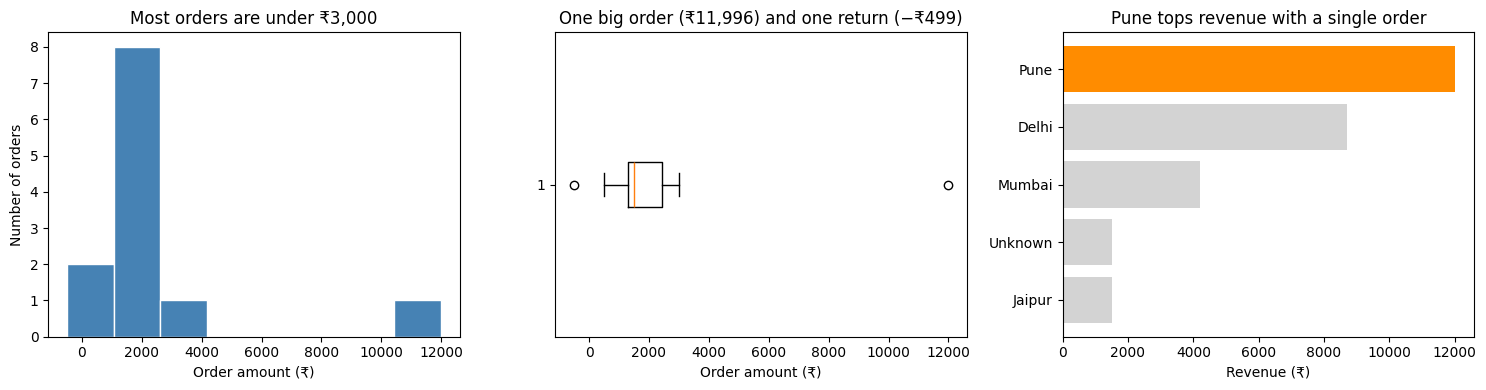

,city,orders,revenue
0,Jaipur,1,1499
1,Unknown,1,1499
2,Mumbai,2,4196
3,Delhi,5,8693
4,Pune,1,11996


In [ ]:
import matplotlib.pyplot as plt

# 1. Raw order amounts (all rows, before cleaning)

amounts = q("SELECT order_id, quantity * price AS amount FROM orders")

# 2. Clean revenue by city: remove the duplicate, drop returns, label the missing city

clean = q("""
SELECT COALESCE(city, 'Unknown') AS city,
       COUNT(*)                  AS orders,
       SUM(quantity * price)     AS revenue
FROM (SELECT DISTINCT * FROM orders) AS o      -- removes the duplicate O3
WHERE quantity > 0                             -- returns kept out of sales
GROUP BY COALESCE(city, 'Unknown')
ORDER BY revenue
""")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Chart 1 – distribution: what is a typical order?

ax[0].hist(amounts['amount'], bins=8, color='steelblue', edgecolor='white')
ax[0].set_title('Most orders are under ₹3,000')
ax[0].set_xlabel('Order amount (₹)')
ax[0].set_ylabel('Number of orders')

# Chart 2 – outliers: the box plot shows the unusual values

ax[1].boxplot(amounts['amount'], vert=False)
ax[1].set_title('One big order (₹11,996) and one return (−₹499)')
ax[1].set_xlabel('Order amount (₹)')

# Chart 3 – clean result: revenue by city, highlight the surprise

colors = ['darkorange' if c == 'Pune' else 'lightgrey' for c in clean['city']]
ax[2].barh(clean['city'], clean['revenue'], color=colors)
ax[2].set_title('Pune tops revenue with a single order')
ax[2].set_xlabel('Revenue (₹)')

plt.tight_layout()
plt.show()
clean

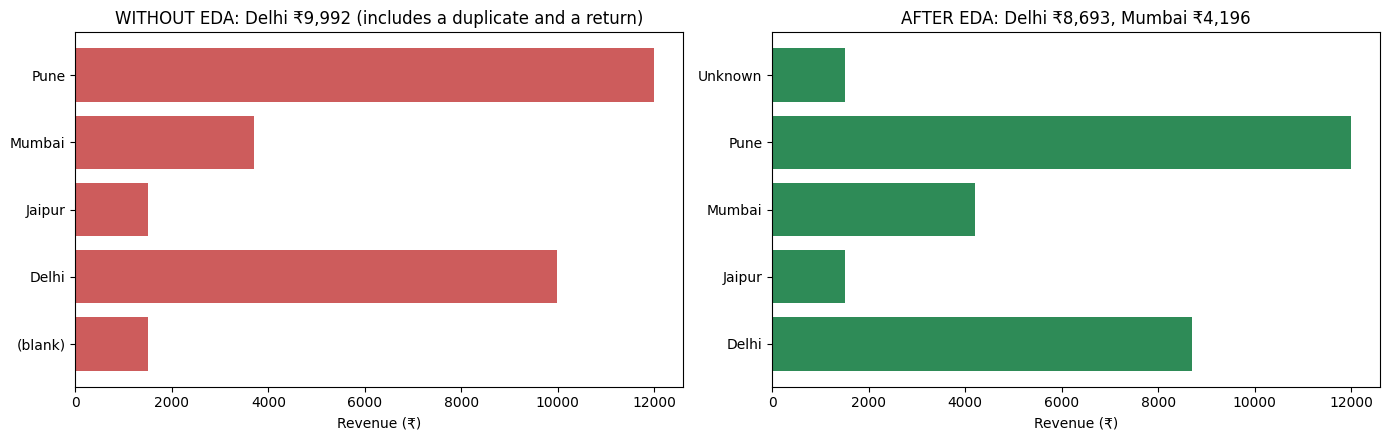

Total revenue without EDA: ₹ 28683 | after EDA: ₹ 27883


,without_EDA,after_EDA,difference
city,,,
(blank),1499,0,-1499
Delhi,9992,8693,-1299
Jaipur,1499,1499,0
Mumbai,3697,4196,499
Pune,11996,11996,0
Unknown,0,1499,1499


In [ ]:
import matplotlib.pyplot as plt

# WITHOUT EDA – straight from the raw table
raw = q("""
SELECT city, COUNT(*) AS orders, SUM(quantity * price) AS revenue
FROM orders
GROUP BY city
""")
raw['city'] = raw['city'].fillna('(blank)')

# AFTER EDA – duplicate removed, returns excluded, missing city labelled
clean = q("""
SELECT COALESCE(city, 'Unknown') AS city, COUNT(*) AS orders, SUM(quantity * price) AS revenue
FROM (SELECT DISTINCT * FROM orders) AS o
WHERE quantity > 0
GROUP BY COALESCE(city, 'Unknown')
""")

# Side-by-side charts, same scale so the bars can be compared
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
ax[0].barh(raw['city'], raw['revenue'], color='indianred')
ax[0].set_title('WITHOUT EDA: Delhi ₹9,992 (includes a duplicate and a return)')
ax[0].set_xlabel('Revenue (₹)')
ax[1].barh(clean['city'], clean['revenue'], color='seagreen')
ax[1].set_title('AFTER EDA: Delhi ₹8,693, Mumbai ₹4,196')
ax[1].set_xlabel('Revenue (₹)')
plt.tight_layout()
plt.show()

# The numbers behind the charts
compare = (raw.set_index('city')[['revenue']].rename(columns={'revenue': 'without_EDA'})
           .join(clean.set_index('city')[['revenue']].rename(columns={'revenue': 'after_EDA'}), how='outer')
           .fillna(0).astype(int))
compare['difference'] = compare['after_EDA'] - compare['without_EDA']
print('Total revenue without EDA: ₹', raw['revenue'].sum(), '| after EDA: ₹', clean['revenue'].sum())
compare

### 📊 Why EDA Matters: A Case Study in 12 Rows

Both charts look equally professional, but **only one is right**. This case study compares data before and after Exploratory Data Analysis (EDA) using a small sample of just 12 orders:

| City | Without EDA (Raw Data) | After EDA (Cleaned) | The Reality Behind the Data |
| :--- | :--- | :--- | :--- |
| **Delhi** | ₹9,992 (6 orders) | **₹8,693 (5 orders)** | ❌ Duplicate order counted twice (₹1,299 too high). |
| **Mumbai** | ₹3,697 | **₹4,196** | ❌ A ₹499 return was wrongly subtracted (₹499 too low). |
| **(blank)** | ₹1,499 under empty label | **Labelled "Unknown"** | ❌ Missing city hidden in plain sight. |
| **Pune** | ₹11,996 | **₹11,996** | ❌ Looked like multiple sales, but EDA proved it's just 1 order. |
| **Total** | **₹28,683** | **₹27,883** | ⚠️ **Overall revenue was off by ₹800.** |

#### 🔑 The Main Takeaway
* **Without EDA:** A confident, professional-looking chart with completely wrong numbers.
* **With EDA:** The right numbers, backed by structural understanding.

If a tiny 12-row dataset can hide duplicate orders, mishandled returns, and missing labels that throw off total revenue by ₹800, imagine the scale of errors in a company processing lakhs of orders. **A chart is only as trustworthy as the checks done before it.**


---
## Part 0 – Set up (5 minutes)

### The online-store database
Three tables linked by **keys** (IDs):

| Table | One row is… | Columns | Key |
|---|---|---|---|
| `customers` (300) | a customer | `customer_id`, `city`, `segment`, `signup_year` | **primary key** `customer_id` |
| `products` (20) | a product | `product_id`, `product`, `category`, `unit_price` (₹) | **primary key** `product_id` |
| `orders` (1,500) | an order line | `order_id`, `order_date`, `customer_id`, `product_id`, `quantity`, `payment_mode` | `customer_id` and `product_id` are **foreign keys** |

```
customers (customer_id) ──< orders >── (product_id) products
```

### Step 0.1 📖 Libraries and file upload
Upload **customers.csv, products.csv, orders.csv, delhi_air_quality_2025.csv** when the button appears (or use the folder icon on the left).

### Step 0.2 📖 Load the CSV files into a SQL database
**SQLite** is a small database built into Python – nothing to install. We copy each CSV into a table, then write SQL with the helper `q("...")`, which returns the answer as a pandas table.

In [10]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 20)

FILES = ['customers.csv', 'products.csv', 'orders.csv', 'delhi_air_quality_2025.csv']
DATA = 'data/' if os.path.exists('data/' + FILES[0]) else ''
missing = [f for f in FILES if not os.path.exists(DATA + f)]
if missing:
    try:
        from google.colab import files
        print('Please choose these files:', missing)
        files.upload()
        DATA = ''
    except ImportError:
        print('Not in Colab: put the CSV files next to this notebook (or in a data/ folder).')
for f in FILES:
    print('✅ found  ' if os.path.exists(DATA + f) else '❌ MISSING', f)

Please choose these files: ['customers.csv', 'products.csv', 'orders.csv']


Saving customers.csv to customers.csv
Saving orders.csv to orders.csv
Saving products.csv to products.csv
✅ found   customers.csv
✅ found   products.csv
✅ found   orders.csv
✅ found   delhi_air_quality_2025.csv


In [12]:
customers = pd.read_csv(DATA + 'customers.csv')
products = pd.read_csv(DATA + 'products.csv')
orders = pd.read_csv(DATA + 'orders.csv', parse_dates=['order_date'])
aq = pd.read_csv(DATA + 'delhi_air_quality_2025.csv', parse_dates=['date'])

con = sqlite3.connect(':memory:')                 # a database that lives in memory
customers.to_sql('customers', con, index=False)
products.to_sql('products', con, index=False)
orders.assign(order_date=orders['order_date'].dt.strftime('%Y-%m-%d')).to_sql('orders', con, index=False)
aq.assign(date=aq['date'].dt.strftime('%Y-%m-%d')).to_sql('air_quality', con, index=False)

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return pd.read_sql_query(sql, con)

def check(task, your_answer, expected):
    try:
        ok = your_answer == expected or (isinstance(expected, float) and abs(float(your_answer) - expected) < 0.01)
    except Exception:
        ok = False
    print(f'✅ {task}: correct!' if ok else f'🔁 {task}: you got {your_answer!r}. Expected {expected!r}. Have another look.')

print(q("SELECT name AS table_name FROM sqlite_master WHERE type = 'table'"))

    table_name
0    customers
1     products
2       orders
3  air_quality


---
## Part A – SQL basics (20 minutes)
**SQL (Structured Query Language)** is how you ask questions of a database. Almost every data job posting asks for it.

A query is written in this order:
```sql
SELECT   columns          -- what to show
FROM     table            -- where the data is
WHERE    condition        -- which rows to keep
ORDER BY column DESC      -- how to sort
LIMIT    5                -- how many rows to show
```
### A1 📖 Look at the first rows

In [13]:
q("SELECT * FROM orders LIMIT 5")

,order_id,order_date,customer_id,product_id,quantity,payment_mode
0,O00001,2025-01-01,C190,P05,2,UPI
1,O00002,2025-01-01,C158,P05,1,UPI
2,O00003,2025-01-01,C219,P04,1,Cash on Delivery
3,O00004,2025-01-01,C293,P02,2,UPI
4,O00005,2025-01-02,C195,P13,1,Cash on Delivery


### A2 ✍️ How many orders are there?
`COUNT(*)` counts rows. `AS n` gives the result column a name.



In [15]:
res = q("SELECT COUNT(*) AS n FROM orders")
print(res)
check('A2 count orders', int(res['n'][0]), 1500)

      n
0  1500
✅ A2 count orders: correct!


###  A3 ✍️: Filter with WHERE
Count the orders paid by **UPI**. Text values go in single quotes: `'UPI'`.

In [16]:
res = q("SELECT COUNT(*) AS n FROM orders WHERE payment_mode = 'UPI' ")
print(res)
check('A3 UPI orders', int(res['n'][0]), 818)

     n
0  818
✅ A3 UPI orders: correct!


### A4 ✍️ Sort and Limit
Show the **3 most expensive products** (highest `unit_price` first).

**Expected:** Smart Watch, Sneakers, Bluetooth Speaker

In [17]:
res = q("""
SELECT product, category, unit_price
FROM products
ORDER BY unit_price DESC, product
LIMIT 3
""")
print(res)
check('A4 top 3 products', list(res['product']), ['Smart Watch', 'Sneakers', 'Bluetooth Speaker'])

             product     category  unit_price
0        Smart Watch  Electronics        2999
1           Sneakers      Fashion        1999
2  Bluetooth Speaker  Electronics        1799
✅ A4 top 3 products: correct!


---
## Part B – GROUP BY, JOIN and friends (25 minutes)

### B1 📖 GROUP BY: one answer per group
`GROUP BY payment_mode` makes one row per payment mode; `COUNT(*)` counts the orders in each.

In [18]:
q("""
SELECT payment_mode, COUNT(*) AS orders
FROM orders
GROUP BY payment_mode
ORDER BY orders DESC
""")

,payment_mode,orders
0,UPI,818
1,Card,303
2,Cash on Delivery,266
3,Net Banking,113


### B2 📖 JOIN: combine two tables
`orders` has `product_id` but no price. `JOIN products ON ...` adds the matching product row, so we can compute revenue = quantity × unit_price.




In [19]:
q("""
SELECT o.order_id, o.order_date, p.product, p.category, o.quantity, p.unit_price,
       o.quantity * p.unit_price AS amount
FROM orders AS o
JOIN products AS p ON o.product_id = p.product_id
LIMIT 5
""")

,order_id,order_date,product,category,quantity,unit_price,amount
0,O00001,2025-01-01,Kurti,Fashion,2,799,1598
1,O00002,2025-01-01,Kurti,Fashion,1,799,799
2,O00003,2025-01-01,Bluetooth Speaker,Electronics,1,1799,1799
3,O00004,2025-01-01,Power Bank,Electronics,2,999,1998
4,O00005,2025-01-02,Water Bottle,Home & Kitchen,1,349,349


### B3 ✍️  Revenue by Category
Join `orders` and `products`, then `GROUP BY` category and `SUM` the amount.

**Expected top category:** `Electronics`

In [20]:
res = q("""
SELECT p.category, SUM(o.quantity * p.unit_price) AS revenue
FROM orders AS o
JOIN products AS p ON o.product_id = p.product_id
GROUP BY category
ORDER BY revenue DESC
""")
print(res)
check('B3 top category', res['category'][0], 'Electronics')

             category  revenue
0         Electronics  1285673
1             Fashion   858264
2      Home & Kitchen   307625
3  Books & Stationery   241753
4              Beauty   162853
✅ B3 top category: correct!


### B4 ✍️ : Join three tables – Revenue by City
The city is in `customers`, so join all three tables.

**Expected top city:** `Delhi`

In [21]:
res = q("""
SELECT c.city, COUNT(*) AS orders, SUM(o.quantity * p.unit_price) AS revenue
FROM orders AS o
JOIN products  AS p ON o.product_id  = p.product_id
JOIN customers AS c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY revenue DESC
""")
print(res)
check('B4 top city', res['city'][0], 'Delhi')

         city  orders  revenue
0       Delhi     270   510326
1      Mumbai     223   425520
2     Chennai     198   379312
3   Bengaluru     206   342656
4     Kolkata     153   308289
5      Jaipur     107   219568
6   Hyderabad     115   206621
7     Lucknow      72   170395
8        Pune      86   167768
9  Chandigarh      70   125713
✅ B4 top city: correct!


### B5 ✍️ : HAVING filters groups
`WHERE` filters **rows** before grouping; `HAVING` filters **groups** after.
                                                                               
How many cities have **more than 150 orders**?

In [24]:
res = q("""
SELECT c.city, COUNT(*) AS orders
FROM orders AS o JOIN customers AS c ON o.customer_id = c.customer_id
GROUP BY c.city
HAVING COUNT(*) > 150
""")
print(res)
check('B5 cities with >150 orders', len(res), 5)

        city  orders
0  Bengaluru     206
1    Chennai     198
2      Delhi     270
3    Kolkata     153
4     Mumbai     223
✅ B5 cities with >150 orders: correct!


### B6 ✍️ : LEFT JOIN finds what is missing
A `LEFT JOIN` keeps **every** customer, even those with no orders (their order columns are empty = `NULL`).

How many customers have **never ordered**?

**Why it matters:** these are customers a marketing team could win back.

In [25]:
res = q("""
SELECT c.customer_id, c.city, c.segment
FROM customers AS c
LEFT JOIN orders AS o ON c.customer_id = o.customer_id
WHERE o.order_id IS NULL
""")
print(len(res), 'customers never ordered')
check('B6 customers with no orders', len(res), 52)

52 customers never ordered
✅ B6 customers with no orders: correct!


### B7 📖 One window function: running total by month
A **window function** calculates across rows **without** collapsing them. `SUM(...) OVER (ORDER BY month)` gives a running (cumulative) total.

In [26]:
monthly = q("""
SELECT strftime('%m', o.order_date) AS month,
       SUM(o.quantity * p.unit_price) AS revenue,
       SUM(SUM(o.quantity * p.unit_price)) OVER (ORDER BY strftime('%m', o.order_date)) AS running_total
FROM orders AS o JOIN products AS p ON o.product_id = p.product_id
GROUP BY month
ORDER BY month
""")
print(monthly)
check('B7 December running total = total revenue', int(monthly['running_total'].iloc[-1]), 2856168)

   month  revenue  running_total
0     01   221504         221504
1     02   202457         423961
2     03   180797         604758
3     04   194795         799553
4     05   169505         969058
5     06   251924        1220982
6     07   169394        1390376
7     08   229831        1620207
8     09   179209        1799416
9     10   357010        2156426
10    11   409123        2565549
11    12   290619        2856168
✅ B7 December running total = total revenue: correct!


---
## Part C – The same question in pandas (10 minutes)
SQL and pandas answer the same questions. Analysts use SQL to **get** data from a database and pandas to **work** with it in Python.

| SQL | pandas |
|---|---|
| `JOIN products ON ...` | `orders.merge(products, on='product_id')` |
| `WHERE payment_mode = 'UPI'` | `df[df['payment_mode'] == 'UPI']` |
| `GROUP BY category` + `SUM(amount)` | `df.groupby('category')['amount'].sum()` |
| `ORDER BY revenue DESC` | `.sort_values(ascending=False)` |
| `LIMIT 5` | `.head(5)` |

### C1 ✍️ : Revenue by Category in pandas
**Expected top category:** `Electronics` (same as B3)

In [29]:
sales = orders.merge(products, on='product_id').merge(customers, on='customer_id')
sales['amount'] = sales['quantity'] * sales['unit_price']
by_cat = sales.groupby('category')['amount'].sum().sort_values(ascending=False)
print(by_cat)
check('C1 top category (pandas)', by_cat.index[0], 'Electronics')

category
Electronics           1285673
Fashion                858264
Home & Kitchen         307625
Books & Stationery     241753
Beauty                 162853
Name: amount, dtype: int64
✅ C1 top category (pandas): correct!


---
## Part D – Charts that answer a question (15 minutes)

| Question | Chart |
|---|---|
| How does it change over time? | **Line** |
| Which group is biggest? | **Bar** (horizontal if labels are long) |
| How are values spread? | **Histogram** |
| How do groups compare in spread, with outliers? | **Box plot** |
| Do two numbers move together? | **Scatter** |

**Rules:** one question per chart · the title states the answer · axes labelled with units · no 3-D, no pie with many slices.

### E1 📖 Line: monthly revenue

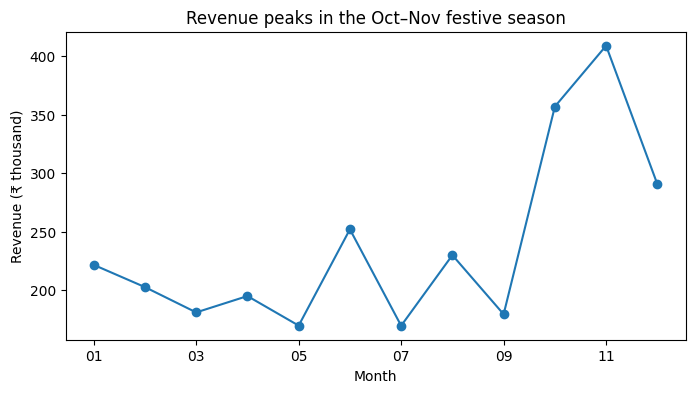

In [31]:
ax = (monthly.set_index('month')['revenue'] / 1000).plot(marker='o', figsize=(8, 4),
        title='Revenue peaks in the Oct–Nov festive season')
ax.set_xlabel('Month'); ax.set_ylabel('Revenue (₹ thousand)')
plt.show()

### D2 ✍️  Bar chart of Revenue by City
Use `by_city` and `kind='barh'`. Write a title that states the answer.

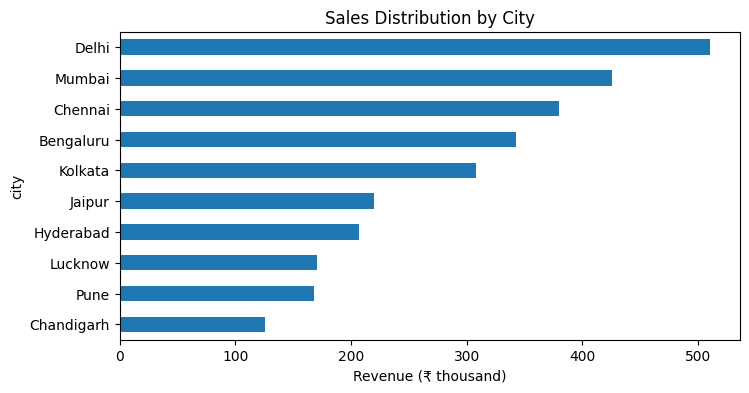

In [32]:
by_city = sales.groupby('city')['amount'].sum().sort_values() / 1000
ax = by_city.plot(kind='barh', figsize=(8, 4), title='Sales Distribution by City')
ax.set_xlabel('Revenue (₹ thousand)')
plt.show()

### D3 📖 Histogram and box plot

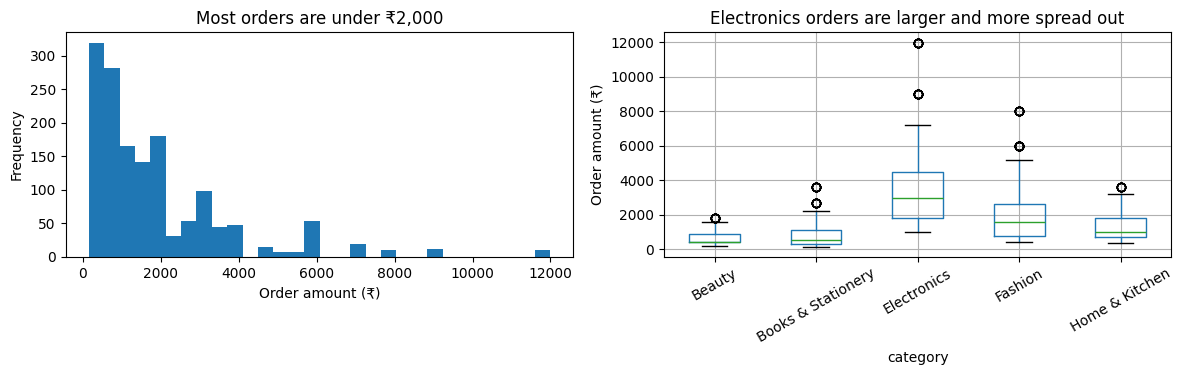

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sales['amount'].plot(kind='hist', bins=30, ax=axes[0], title='Most orders are under ₹2,000')
axes[0].set_xlabel('Order amount (₹)')
sales.boxplot(column='amount', by='category', ax=axes[1], rot=30)
axes[1].set_title('Electronics orders are larger and more spread out'); axes[1].set_ylabel('Order amount (₹)')
plt.suptitle(''); plt.tight_layout(); plt.show()

---
## Part E – Case study CS-02: Air-quality patterns by season and station (20 minutes · groups)

### The situation
Citizens and city officials want to understand Delhi's pollution across the year. Your team is asked:
> *"When and where is the air worst, and what should the city watch for?"*

### The data: table `air_quality` (from `delhi_air_quality_2025.csv`)
| Column | Meaning |
|---|---|
| `date`, `station` | Day and monitoring station (5 stations, 365 days) |
| `pm25`, `pm10` | Fine and coarse particles (µg/m³) |
| `aqi` | Air Quality Index (higher = worse) |
| `aqi_category` | Good / Satisfactory / Moderate / Poor / Very Poor / Severe |

### Tasks
| # | Task | Tool |
|---|---|---|
| F1 | Average AQI by month (SQL) | `GROUP BY` |
| F2 | Average AQI by station (SQL) | `GROUP BY`, `ORDER BY` |
| F3 | Count 'Severe' days per station (SQL) | `WHERE` + `GROUP BY` |
| F4 | Month × station heatmap | pandas `pivot_table` |
| F5 | Five charts, each with a one-line insight | matplotlib |
| F6 | Discussion and one-page insight brief | thinking! |

### E1 ✍️ Average AQI by month
`strftime('%m', date)` takes the month out of a date. **Expected worst month:** `11`

In [36]:
by_month = q("""
SELECT strftime('%m', date) AS month, ROUND(AVG(aqi), 0) AS avg_aqi
FROM air_quality
GROUP BY month
ORDER BY month
""")
print(by_month)
worst = by_month.sort_values('avg_aqi', ascending=False)['month'].iloc[0]
check('E1 worst month', worst, '11')

   month  avg_aqi
0     01    313.0
1     02    252.0
2     03    167.0
3     04    143.0
4     05    165.0
5     06    115.0
6     07     64.0
7     08     62.0
8     09     74.0
9     10    256.0
10    11    360.0
11    12    321.0
✅ E1 worst month: correct!


### E2 ✍️ Average AQI by station, worst first
**Expected worst station:** `Anand Vihar`

In [38]:
by_station = q("""
SELECT station, ROUND(AVG(aqi), 0) AS avg_aqi
FROM air_quality
GROUP BY station
ORDER BY avg_aqi DESC
""")
print(by_station)
check('E2 worst station', by_station['station'][0], 'Anand Vihar')

       station  avg_aqi
0  Anand Vihar    227.0
1          ITO    205.0
2    R K Puram    186.0
3       Dwarka    174.0
4   Lodhi Road    162.0
✅ E2 worst station: correct!


### E3 ✍️ 'Severe' days per station
**Expected for Anand Vihar:** `17`

In [39]:
severe = q("""
SELECT station, COUNT(*) AS severe_days
FROM air_quality
WHERE aqi_category = 'Severe'
GROUP BY station
ORDER BY severe_days DESC
""")
print(severe)
av = int(severe.loc[severe['station'] == 'Anand Vihar', 'severe_days'].iloc[0])
check('E3 Anand Vihar severe days', av, 17)

       station  severe_days
0  Anand Vihar           17
1    R K Puram            5
2          ITO            5
3       Dwarka            3
4   Lodhi Road            1
✅ E3 Anand Vihar severe days: correct!


### E4 📖 Month × station heatmap

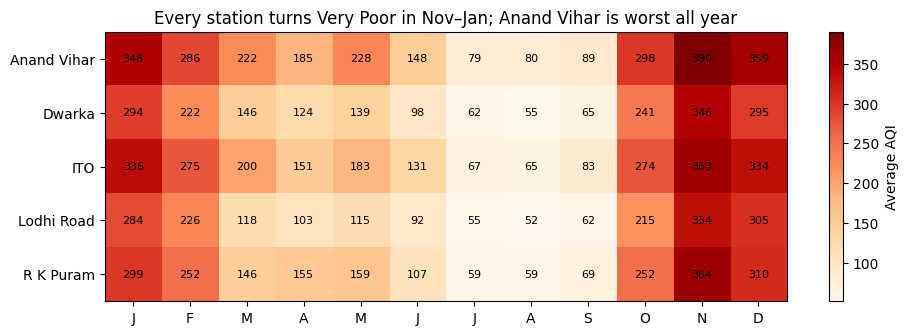

In [40]:
aq['month'] = aq['date'].dt.month
heat = aq.pivot_table(index='station', columns='month', values='aqi', aggfunc='mean').round(0)
fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(heat.values, cmap='OrRd', aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, int(heat.values[i, j]), ha='center', va='center', fontsize=8)
ax.set_title('Every station turns Very Poor in Nov–Jan; Anand Vihar is worst all year')
plt.colorbar(im, label='Average AQI'); plt.show()

### E5 ✍️ Five charts, one insight each
Make **five** charts from the air-quality data. Under each, write one sentence starting *"This shows that…"*. Ideas:
1. Line – average AQI by month
2. Bar – average AQI by station
3. Stacked or grouped bar – days in each `aqi_category` per station
4. Histogram – distribution of `pm25`
5. Scatter – `pm25` vs `pm10` (do they move together?)

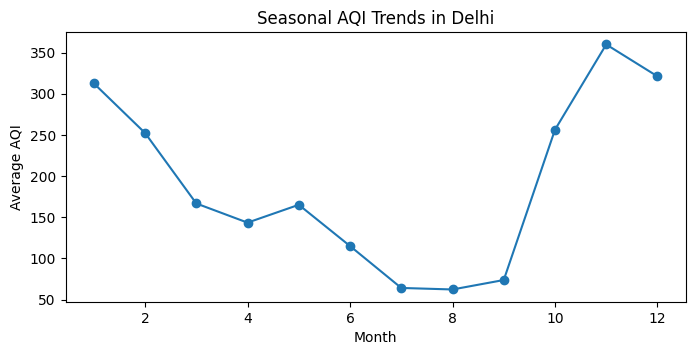

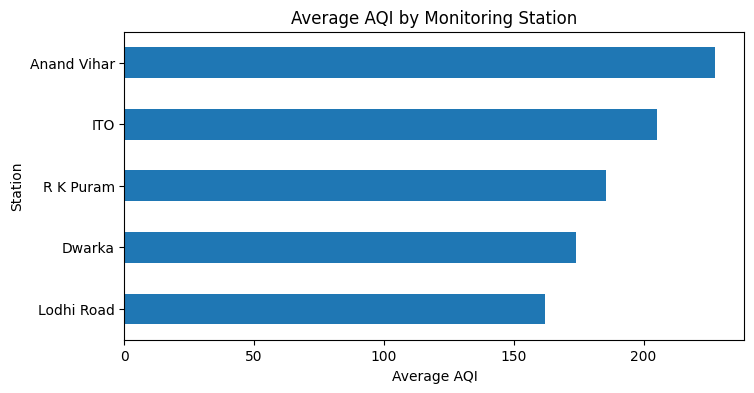

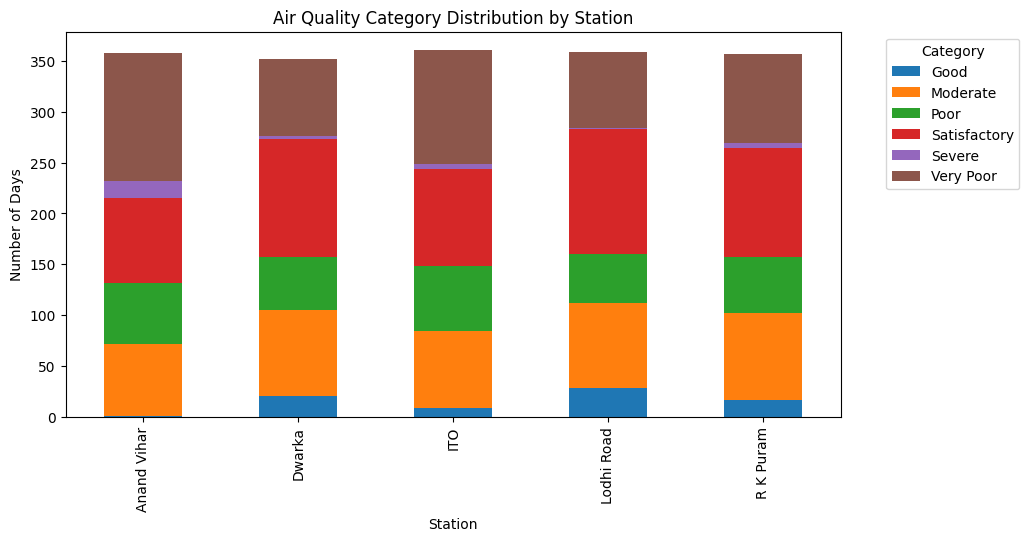

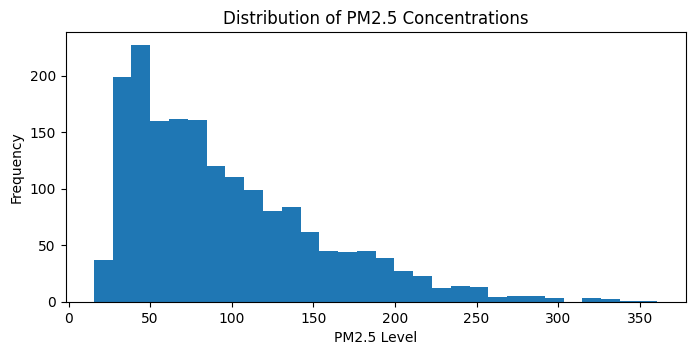

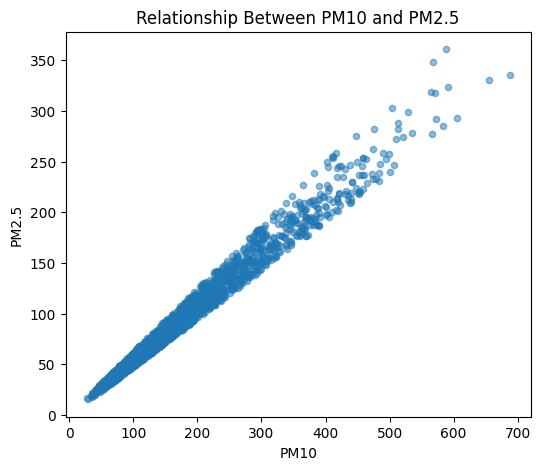

In [42]:
# Chart 1 – line: average AQI by month
# Suggestion for title: 'Seasonal AQI Trends in Delhi'
ax = aq.groupby('month')['aqi'].mean().plot(marker='o', figsize=(8, 3.5), title='Seasonal AQI Trends in Delhi')
ax.set_xlabel('Month'); ax.set_ylabel('Average AQI'); plt.show()
# This shows that air pollution is highly seasonal, peaking drastically during winter months.

# Chart 2 – bar: average AQI by station
ax = aq.groupby('station')['aqi'].mean().sort_values().plot(kind='barh', figsize=(8, 4), title='Average AQI by Monitoring Station')
ax.set_xlabel('Average AQI'); ax.set_ylabel('Station'); plt.show()
# This shows that air quality varies by location, with certain industrial or high-traffic areas suffering more.

# Chart 3 – days per category per station
ax = pd.crosstab(aq['station'], aq['aqi_category']).plot(kind='bar', stacked=True, figsize=(10, 5), title='Air Quality Category Distribution by Station')
ax.set_xlabel('Station'); ax.set_ylabel('Number of Days'); plt.legend(title='Category', bbox_to_anchor=(1.05, 1)); plt.show()
# This shows that severe or hazardous pollution days are concentrated heavily in specific high-exposure stations.

# Chart 4 – histogram of pm25
ax = aq['pm25'].plot(kind='hist', bins=30, figsize=(8, 3.5), title='Distribution of PM2.5 Concentrations')
ax.set_xlabel('PM2.5 Level'); ax.set_ylabel('Frequency'); plt.show()
# This shows that PM2.5 levels are right-skewed, meaning extreme toxic spikes occur regularly beyond typical baseline days.

# Chart 5 – scatter pm25 vs pm10
ax = aq.plot(kind='scatter', x='pm10', y='pm25', alpha=0.5, figsize=(6, 5), title='Relationship Between PM10 and PM2.5')
ax.set_xlabel('PM10'); ax.set_ylabel('PM2.5'); plt.show()
# This shows that PM2.5 and PM10 move tightly together, confirming they likely stem from the same underlying pollution sources.

